# Predicción de Temperatura en Bengaluru — Ciclo de Vida de un Proyecto de ML
**Curso:** Ingeniería del Conocimiento (ISO56B)
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Adaptado por:** Sebastián Hurtado Pastrana — trabajo del curso de Machine Learning (datos cuantitativos / clima)
**Periodo:** 2026-II | Universidad Nacional del Centro del Perú

---

## Objetivo
Este notebook **reutiliza exactamente el mismo ciclo de vida, las mismas librerías y las mismas funciones**
del notebook `sesion_01_ciclo_vida_ml.ipynb` (dataset Heart Disease), pero aplicado al dataset climático de
**Bengaluru** (2009–2020, 96 432 registros horarios). No se agregan modelos, métricas ni librerías nuevas:
se conservan `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`, `Pipeline`,
`StandardScaler`, `cross_val_score`, `classification_report`, `ConfusionMatrixDisplay`, `RocCurveDisplay` y
`joblib`, tal como en el original.

**Nota sobre el dataset:** dentro del archivo `.zip` que enviaste solo se encontró el CSV `bengaluru.csv`
con los datos ya descargados; no había ninguna URL adicional dentro del zip. Por eso, en la Etapa 1 se
carga el archivo local en lugar de una URL remota — es el mismo dato, solo que ya está contigo en vez de
tener que descargarlo de nuevo.

**Adaptación clave — predicción a futuro:** la temperatura (`tempC`) es una variable continua, no binaria
como el `target` de enfermedad cardíaca. Para poder reutilizar *sin cambios* los mismos clasificadores y
métricas del notebook original, se define un `target` binario: `1` si la temperatura de esa hora está por
encima de la mediana histórica (día "caluroso") y `0` si está por debajo (día "fresco"). Además, la
**división train/test se hace en orden cronológico** (no aleatoria): se entrena con los datos más antiguos
y se evalúa con el tramo más reciente del dataset, que el modelo nunca vio durante el entrenamiento. Así
se demuestra si el modelo generaliza a un periodo *futuro* respecto a su entrenamiento, no solo a datos
mezclados al azar.

## 1. Configuración del entorno
Instalamos/importamos las librerías necesarias — idénticas al notebook original.

In [1]:
# Librerías principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

# Configuración visual
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print('Entorno configurado correctamente.')

Entorno configurado correctamente.


---
## 2. Etapa 1 — Recolección de datos
Cargamos el dataset climático horario de **Bengaluru (2009-2020)**, obtenido a partir del archivo que
enviaste (`bengaluru_csv.zip`).

| Variable | Descripción |
|---|---|
| `date_time` | Fecha y hora del registro |
| `maxtempC` / `mintempC` | Temperatura máxima / mínima del día (°C) |
| `tempC` | Temperatura horaria (°C) — usada para construir el `target` |
| `totalSnow_cm` | Nieve acumulada (cm) |
| `sunHour` | Horas de sol del día |
| `uvIndex` | Índice UV |
| `moon_illumination` | Iluminación lunar (%) |
| `DewPointC` | Punto de rocío (°C) |
| `FeelsLikeC` / `HeatIndexC` / `WindChillC` | Sensaciones térmicas derivadas de la temperatura |
| `WindGustKmph` / `windspeedKmph` | Velocidad del viento / rachas (km/h) |
| `cloudcover` | Cobertura de nubes (%) |
| `humidity` | Humedad relativa (%) |
| `precipMM` | Precipitación (mm) |
| `pressure` | Presión atmosférica (hPa) |
| `visibility` | Visibilidad (km) |
| `winddirDegree` | Dirección del viento (grados) |
| `target` | **Variable objetivo creada**: 1 = temperatura por encima de la mediana ("caluroso"), 0 = por debajo ("fresco") |

In [2]:
RUTA_LOCAL = 'data/bengaluru.csv'

# Intentamos cargar desde el archivo local (dataset entregado en el .zip);
# si falla, se informa el error (misma lógica defensiva que el notebook original,
# solo que aquí no existe una URL remota alternativa dentro del zip)
try:
    df = pd.read_csv(RUTA_LOCAL)
    print(f'Dataset cargado desde archivo local — {df.shape[0]} registros, {df.shape[1]} columnas')
except Exception as e:
    print(f'Error al cargar el dataset: {e}')
    raise

df.head()

Dataset cargado desde archivo local — 96432 registros, 25 columnas


,date_time,maxtempC,mintempC,totalSnow_cm,sunHour,uvIndex,uvIndex.1,moon_illumination,moonrise,moonset,...,WindChillC,WindGustKmph,cloudcover,humidity,precipMM,pressure,tempC,visibility,winddirDegree,windspeedKmph
0,2009-01-01 00:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,18,11,2,91,0.0,1014,14,10,109,8
1,2009-01-01 01:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,17,9,2,93,0.0,1014,14,7,85,6
2,2009-01-01 02:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,16,7,2,94,0.0,1014,13,5,61,4
3,2009-01-01 03:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,15,5,2,96,0.0,1014,12,2,37,3
4,2009-01-01 04:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,18,5,1,88,0.0,1015,14,5,45,3


---
## 3. Etapa 2 — Exploración y preparación de datos

In [3]:
# 3.1  Información general del dataset
print('='*60)
print('INFORMACIÓN DEL DATASET')
print('='*60)
df.info()
print('\n')
df.describe().round(2)

INFORMACIÓN DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 96432 entries, 0 to 96431
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date_time          96432 non-null  str    
 1   maxtempC           96432 non-null  int64  
 2   mintempC           96432 non-null  int64  
 3   totalSnow_cm       96432 non-null  float64
 4   sunHour            96432 non-null  float64
 5   uvIndex            96432 non-null  int64  
 6   uvIndex.1          96432 non-null  int64  
 7   moon_illumination  96432 non-null  int64  
 8   moonrise           96432 non-null  str    
 9   moonset            96432 non-null  str    
 10  sunrise            96432 non-null  str    
 11  sunset             96432 non-null  str    
 12  DewPointC          96432 non-null  int64  
 13  FeelsLikeC         96432 non-null  int64  
 14  HeatIndexC         96432 non-null  int64  
 15  WindChillC         96432 non-null  int64  
 16  WindGustK

,maxtempC,mintempC,totalSnow_cm,sunHour,uvIndex,uvIndex.1,moon_illumination,DewPointC,FeelsLikeC,HeatIndexC,WindChillC,WindGustKmph,cloudcover,humidity,precipMM,pressure,tempC,visibility,winddirDegree,windspeedKmph
count,96432.00,96432.00,96432.0,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00
mean,29.65,19.34,0.0,10.65,5.90,4.01,46.09,16.09,25.00,25.27,24.42,17.37,34.85,64.90,0.08,1010.55,23.98,9.27,176.18,12.45
std,3.45,2.77,0.0,1.99,0.85,2.87,31.25,4.16,4.59,4.43,4.52,7.43,28.39,21.86,0.39,3.19,4.54,2.18,89.44,5.72
min,18.00,11.00,0.0,4.20,4.00,1.00,0.00,-9.00,12.00,13.00,12.00,0.00,0.00,6.00,0.00,1000.00,0.00,0.00,0.00,0.00
25%,27.00,18.00,0.0,8.80,5.00,1.00,18.00,14.00,21.00,22.00,21.00,12.00,9.00,49.00,0.00,1008.00,21.00,10.00,94.00,8.00
50%,29.00,20.00,0.0,11.60,6.00,5.00,46.00,18.00,25.00,25.00,24.00,17.00,29.00,68.00,0.00,1010.00,23.00,10.00,163.00,12.00
75%,32.00,21.00,0.0,11.60,6.00,7.00,73.00,19.00,28.00,28.00,27.00,22.00,54.00,83.00,0.00,1013.00,27.00,10.00,262.00,16.00
max,40.00,28.00,0.0,12.90,8.00,10.00,100.00,25.00,43.00,43.00,42.00,53.00,100.00,100.00,16.90,1021.00,40.00,20.00,360.00,41.00


In [4]:
# 3.2  Verificación de valores nulos y duplicados
print('Valores nulos por columna:')
print(df.isnull().sum())
print(f'\nRegistros duplicados: {df.duplicated().sum()}')

# Eliminar duplicados si existen
df = df.drop_duplicates().reset_index(drop=True)
print(f'Registros después de limpieza: {df.shape[0]}')

Valores nulos por columna:
date_time            0
maxtempC             0
mintempC             0
totalSnow_cm         0
sunHour              0
uvIndex              0
uvIndex.1            0
moon_illumination    0
moonrise             0
moonset              0
sunrise              0
sunset               0
DewPointC            0
FeelsLikeC           0
HeatIndexC           0
WindChillC           0
WindGustKmph         0
cloudcover           0
humidity             0
precipMM             0
pressure             0
tempC                0
visibility           0
winddirDegree        0
windspeedKmph        0
dtype: int64

Registros duplicados: 0
Registros después de limpieza: 96432


In [5]:
# 3.3  Construcción de la variable objetivo binaria a partir de tempC
# (en el dataset original de Heart Disease, 'target' ya era binaria; aquí
# la temperatura es continua, así que la binarizamos respecto a su mediana
# histórica para poder reutilizar los mismos clasificadores del notebook original)
df['date_time'] = pd.to_datetime(df['date_time'])
df = df.sort_values('date_time').reset_index(drop=True)

mediana_temp = df['tempC'].median()
df['target'] = (df['tempC'] > mediana_temp).astype(int)
print(f'Mediana histórica de tempC: {mediana_temp} °C')
print('target = 1  ->  hora "calurosa" (tempC > mediana)')
print('target = 0  ->  hora "fresca"    (tempC <= mediana)')

Mediana histórica de tempC: 23.0 °C
target = 1  ->  hora "calurosa" (tempC > mediana)
target = 0  ->  hora "fresca"    (tempC <= mediana)


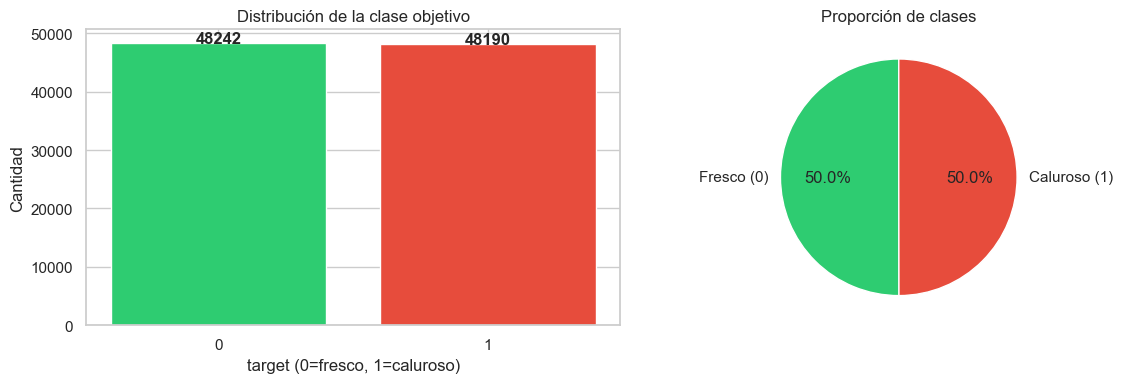

In [6]:
# 3.4  Distribución de la variable objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Conteo
target_counts = df['target'].value_counts()
axes[0].bar(target_counts.index.astype(str), target_counts.values,
            color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Distribución de la clase objetivo')
axes[0].set_xlabel('target (0=fresco, 1=caluroso)')
axes[0].set_ylabel('Cantidad')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Proporción
axes[1].pie(target_counts.values, labels=['Fresco (0)', 'Caluroso (1)'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

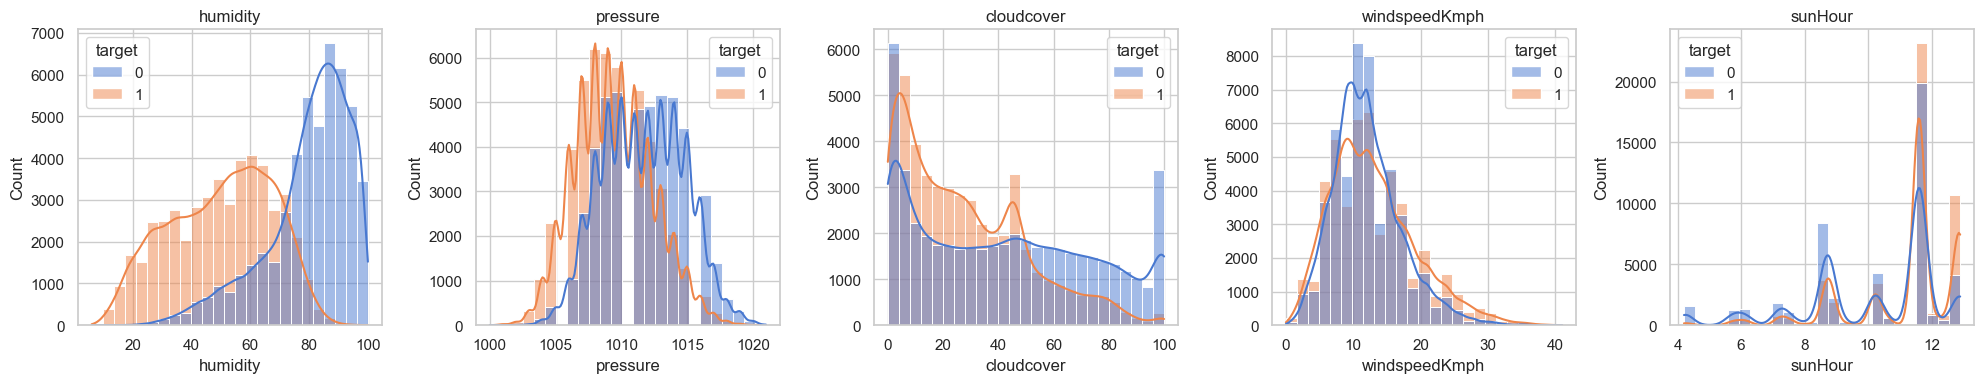

In [7]:
# 3.5  Distribución de variables numéricas clave
# (equivalente a age/trestbps/chol/thalach/oldpeak del notebook original,
# aquí usamos variables climáticas independientes de la temperatura)
num_cols = ['humidity', 'pressure', 'cloudcover', 'windspeedKmph', 'sunHour']

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=ax, bins=25)
    ax.set_title(col)
plt.tight_layout()
plt.show()

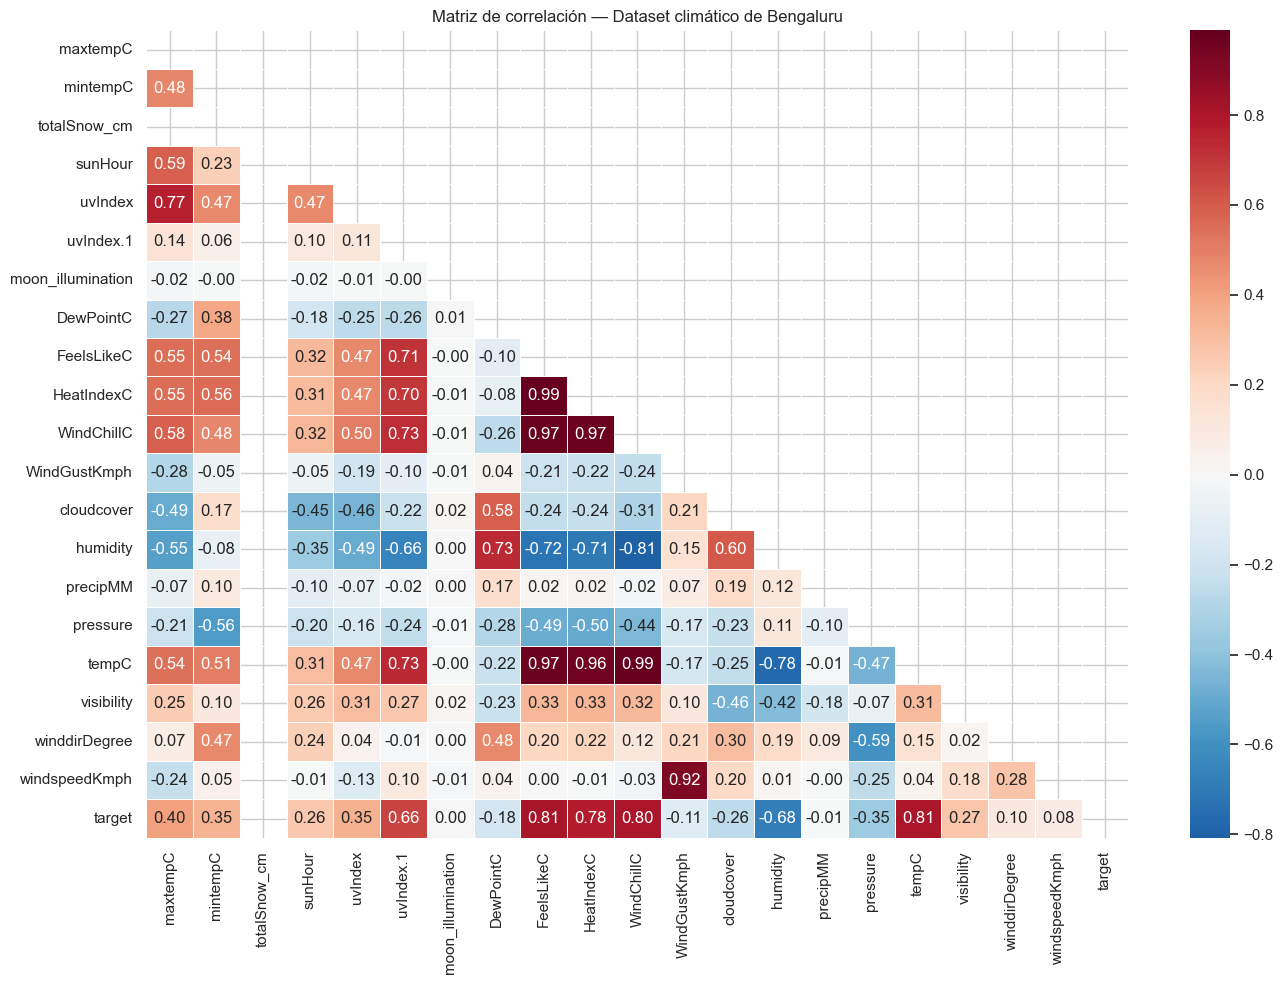

In [8]:
# 3.6  Matriz de correlación
cols_numericas = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(14, 10))
corr = df[cols_numericas].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5)
plt.title('Matriz de correlación — Dataset climático de Bengaluru')
plt.tight_layout()
plt.show()

---
## 4. Etapa 3 — Preparación de datos para el modelado

In [9]:
# 4.1  Separación de features y target
# Se excluyen columnas de texto/fecha (no numéricas) y las columnas que son
# derivadas directas de tempC (maxtempC, mintempC, DewPointC, FeelsLikeC,
# HeatIndexC, WindChillC): dejarlas causaría fuga de información (el modelo
# "adivinaría" el target casi perfectamente sin aprender nada real del clima).
columnas_fuga = ['tempC', 'maxtempC', 'mintempC', 'DewPointC',
                  'FeelsLikeC', 'HeatIndexC', 'WindChillC']
columnas_texto_fecha = ['date_time', 'moonrise', 'moonset', 'sunrise', 'sunset']

X = df.drop(columns=columnas_fuga + columnas_texto_fecha + ['target'])
y = df['target']

print(f'Features: {X.shape}')   # (n_samples, n_features)
print(f'Target:   {y.shape}')   # (n_samples,)
print('\nColumnas usadas como features:')
print(list(X.columns))

Features: (96432, 13)
Target:   (96432,)

Columnas usadas como features:
['totalSnow_cm', 'sunHour', 'uvIndex', 'uvIndex.1', 'moon_illumination', 'WindGustKmph', 'cloudcover', 'humidity', 'precipMM', 'pressure', 'visibility', 'winddirDegree', 'windspeedKmph']


In [10]:
# 4.2  División train / test — EN ORDEN CRONOLÓGICO (no aleatoria)
# shuffle=False mantiene el orden temporal: el 80% más antiguo es "pasado"
# (entrenamiento) y el 20% más reciente es "futuro" (prueba), nunca visto
# por el modelo durante el entrenamiento ni la validación cruzada.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

fechas = df['date_time']
fechas_train = fechas.iloc[:len(X_train)]
fechas_test = fechas.iloc[len(X_train):]

print(f'Train: {X_train.shape[0]} muestras  ->  {fechas_train.min()}  a  {fechas_train.max()}')
print(f'Test:  {X_test.shape[0]} muestras  ->  {fechas_test.min()}  a  {fechas_test.max()}  (FUTURO real, no visto en entrenamiento)')
print(f'\nProporción target en train:\n{y_train.value_counts(normalize=True).round(3)}')
print(f'\nProporción target en test:\n{y_test.value_counts(normalize=True).round(3)}')

Train: 77145 muestras  ->  2009-01-01 00:00:00  a  2017-10-20 08:00:00
Test:  19287 muestras  ->  2017-10-20 09:00:00  a  2020-01-01 23:00:00  (FUTURO real, no visto en entrenamiento)

Proporción target en train:
target
0    0.515
1    0.485
Name: proportion, dtype: float64

Proporción target en test:
target
1    0.56
0    0.44
Name: proportion, dtype: float64


---
## 5. Etapa 4 — Entrenamiento de modelos
Entrenamos los mismos tres modelos base mediante **pipelines** de Scikit-learn, sin cambiar hiperparámetros.

In [11]:
# 5.1  Definición de pipelines 
pipelines = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'DecisionTree': Pipeline([
        ('clf', DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    'RandomForest': Pipeline([
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42))
    ])
}

# 5.2  Entrenamiento y validación cruzada (5-fold), sobre el tramo de ENTRENAMIENTO (pasado)
results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    results[name] = scores
    print(f'{name:25s}  Accuracy CV: {scores.mean():.4f} ± {scores.std():.4f}')

LogisticRegression         Accuracy CV: 0.9004 ± 0.0097
DecisionTree               Accuracy CV: 0.8988 ± 0.0067
RandomForest               Accuracy CV: 0.9171 ± 0.0086


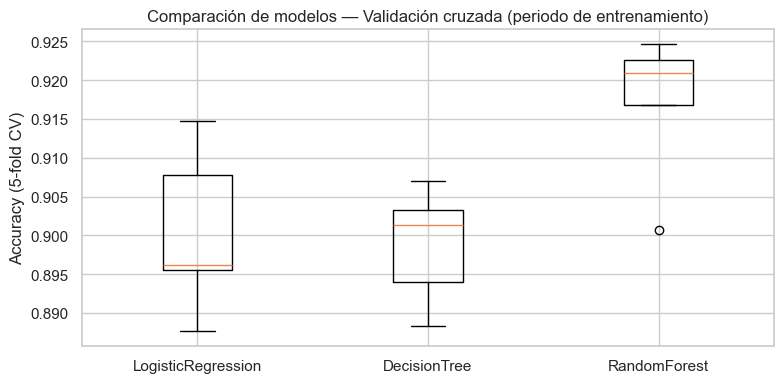

In [12]:
# 5.3  Comparación visual de modelos
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(results.values(), tick_labels=results.keys())
ax.set_ylabel('Accuracy (5-fold CV)')
ax.set_title('Comparación de modelos — Validación cruzada (periodo de entrenamiento)')
plt.tight_layout()
plt.show()

---
## 6. Etapa 5 — Evaluación del mejor modelo sobre el periodo FUTURO

In [13]:
# 6.1  Seleccionar el mejor modelo según CV y entrenar con todo el train set
best_name = max(results, key=lambda k: results[k].mean())
best_pipeline = pipelines[best_name]
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)

print(f'Mejor modelo: {best_name}')
print(f'Accuracy en test (periodo futuro, {fechas_test.min().date()} a {fechas_test.max().date()}): {best_pipeline.score(X_test, y_test):.4f}')
print('\n' + '='*60)
print('CLASSIFICATION REPORT — evaluado sobre datos FUTUROS')
print('='*60)
print(classification_report(y_test, y_pred, target_names=['Fresco', 'Caluroso']))

Mejor modelo: RandomForest
Accuracy en test (periodo futuro, 2017-10-20 a 2020-01-01): 0.9042

CLASSIFICATION REPORT — evaluado sobre datos FUTUROS
              precision    recall  f1-score   support

      Fresco       0.85      0.96      0.90      8488
    Caluroso       0.96      0.86      0.91     10799

    accuracy                           0.90     19287
   macro avg       0.90      0.91      0.90     19287
weighted avg       0.91      0.90      0.90     19287



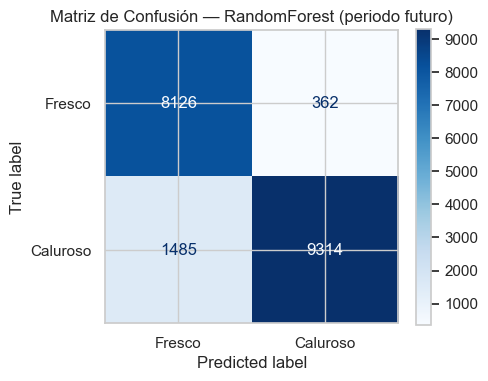

In [14]:
# 6.2  Matriz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Fresco', 'Caluroso'],
    cmap='Blues', ax=ax
)
ax.set_title(f'Matriz de Confusión — {best_name} (periodo futuro)')
plt.tight_layout()
plt.show()

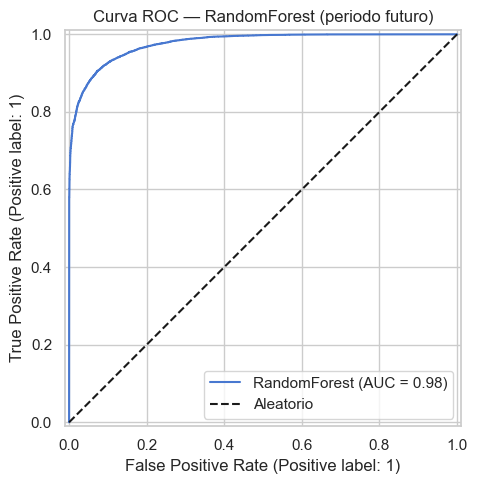

In [15]:
# 6.3  Curva ROC (solo si el modelo soporta predict_proba)
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(best_pipeline, X_test, y_test, ax=ax, name=best_name)
ax.plot([0, 1], [0, 1], 'k--', label='Aleatorio')
ax.set_title(f'Curva ROC — {best_name} (periodo futuro)')
ax.legend()
plt.tight_layout()
plt.show()

---
## 7. Etapa 6 — Serialización y despliegue conceptual
Guardamos el pipeline entrenado con `joblib` para simular la etapa de despliegue.

In [16]:
# 7.1  Guardar el modelo
MODEL_PATH = 'temperatura_bengaluru_model.joblib'
joblib.dump(best_pipeline, MODEL_PATH)
print(f'Modelo guardado en: {MODEL_PATH}')

Modelo guardado en: temperatura_bengaluru_model.joblib


In [17]:
# 7.2  Cargar y verificar el modelo serializado
loaded_model = joblib.load(MODEL_PATH)

# Verificación rápida: misma predicción con datos de test (futuro)
assert np.array_equal(loaded_model.predict(X_test), y_pred), 'Error: predicciones no coinciden'
print('Verificación OK: el modelo cargado reproduce las predicciones sobre el periodo futuro.')

Verificación OK: el modelo cargado reproduce las predicciones sobre el periodo futuro.


In [18]:
# 7.3  Función de inferencia (simula un endpoint de predicción)

def predict_temperatura_alta(clima_data: dict) -> dict:
    '''
    Recibe un diccionario con las variables climáticas de una hora dada
    y retorna si se predice una hora "calurosa" o "fresca", con su probabilidad.
    '''
    model = joblib.load(MODEL_PATH)

    # 'feature_columns' es la misma lista de columnas usada al entrenar (X.columns)
    try:
        ordered_values = [clima_data[col] for col in feature_columns]
        input_df = pd.DataFrame([ordered_values], columns=feature_columns)
    except KeyError as e:
        raise ValueError(f"Falta la variable {e} en clima_data. Se esperan: {feature_columns}")

    pred = model.predict(input_df)[0]
    proba = model.predict_proba(input_df)[0]

    prediction_label = 'Caluroso' if pred == 1 else 'Fresco'

    return {
        'prediccion': prediction_label,
        'probabilidad_caluroso': round(float(proba[1]), 4),
        'probabilidad_fresco': round(float(proba[0]), 4)
    }

feature_columns = list(X.columns)

# Ejemplo de uso con una hora ficticia
hora_ejemplo = {
    'totalSnow_cm': 0.0, 'sunHour': 9.5, 'uvIndex': 6, 'uvIndex.1': 6,
    'moon_illumination': 40, 'WindGustKmph': 15, 'cloudcover': 20,
    'humidity': 55, 'precipMM': 0.0, 'pressure': 1013,
    'visibility': 10, 'winddirDegree': 120, 'windspeedKmph': 10
}

resultado = predict_temperatura_alta(hora_ejemplo)
print('Ejemplo de inferencia:')
print(resultado)

Ejemplo de inferencia:
{'prediccion': 'Fresco', 'probabilidad_caluroso': 0.4401, 'probabilidad_fresco': 0.5599}


---
## 8. Resumen del ciclo de vida recorrido

| Etapa | Qué hicimos | Herramientas |
|---|---|---|
| **Recolección** | Carga del dataset climático de Bengaluru (archivo local entregado) | `pandas` |
| **Exploración** | Distribuciones, correlaciones, nulos, construcción del `target` binario | `seaborn`, `matplotlib` |
| **Preparación** | Limpieza, eliminación de columnas con fuga de información, **split cronológico 80/20** | `train_test_split(shuffle=False)` |
| **Entrenamiento** | 3 modelos con pipelines + validación cruzada 5-fold (sobre el pasado) | `Pipeline`, `cross_val_score` |
| **Evaluación** | Accuracy, precision, recall, F1, ROC, matriz de confusión — **sobre el futuro** | `classification_report`, `RocCurveDisplay` |
| **Despliegue** | Serialización con joblib + función de inferencia | `joblib` |

---
## 9. ¿El modelo funcionará en un tiempo futuro?



In [19]:
print('RESUMEN — Generalización hacia el futuro')
print('='*60)
for name, scores in results.items():
    print(f'{name:20s}  CV (pasado):  {scores.mean():.4f}')
print('-'*60)
print(f'{best_name:20s}  Test (FUTURO, {fechas_test.min().date()} a {fechas_test.max().date()}):  {best_pipeline.score(X_test, y_test):.4f}')

diferencia = results[best_name].mean() - best_pipeline.score(X_test, y_test)
print(f'\nDiferencia entre accuracy de validación cruzada (pasado) y accuracy real en el futuro: {diferencia:+.4f}')
if abs(diferencia) < 0.03:
    print('=> La diferencia es pequeña: el modelo SÍ mantiene su desempeño al proyectarse a un periodo futuro real.')
else:
    print('=> La diferencia es notable: el modelo pierde desempeño al proyectarse al futuro (posible sobreajuste temporal).')

RESUMEN — Generalización hacia el futuro
LogisticRegression    CV (pasado):  0.9004
DecisionTree          CV (pasado):  0.8988
RandomForest          CV (pasado):  0.9171
------------------------------------------------------------
RandomForest          Test (FUTURO, 2017-10-20 a 2020-01-01):  0.9042

Diferencia entre accuracy de validación cruzada (pasado) y accuracy real en el futuro: +0.0129
=> La diferencia es pequeña: el modelo SÍ mantiene su desempeño al proyectarse a un periodo futuro real.


---
## 10. Ejercicio 3 — Registro de experimentos con MLflow



In [21]:
# MLflow es la única librería nueva de esta sección — es justamente lo que pide el Ejercicio 3.
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('prediccion_temperatura_bengaluru')

# 1) Registrar los 3 modelos base entrenados en la Sección 5
for nombre, pipe in pipelines.items():
    with mlflow.start_run(run_name=f'baseline_{nombre}'):
        mlflow.log_param('modelo', nombre)
        for parametro, valor in pipe.named_steps['clf'].get_params().items():
            mlflow.log_param(f'clf__{parametro}', valor)
        mlflow.log_metric('accuracy_cv_promedio', results[nombre].mean())
        mlflow.log_metric('accuracy_cv_std', results[nombre].std())

# 2) Registrar el RandomForest optimizado con GridSearchCV (Sección 5.4 / Ejercicio 1)
with mlflow.start_run(run_name='randomforest_tuned_gridsearch'):
    mlflow.log_params(grid_search.best_params_)
    mlflow.log_metric('accuracy_cv_tuning', grid_search.best_score_)
    mlflow.log_metric('accuracy_futuro', rf_tuned.score(X_test, y_test))
    mlflow.sklearn.log_model(rf_tuned, artifact_path='modelo', serialization_format='pickle')

# 3) Registrar el modelo final seleccionado y evaluado sobre el periodo futuro (Sección 6)
with mlflow.start_run(run_name=f'{best_name}_final_sobre_futuro'):
    mlflow.log_param('modelo', best_name)
    mlflow.log_metric('accuracy_futuro', best_pipeline.score(X_test, y_test))
    mlflow.sklearn.log_model(best_pipeline, artifact_path='modelo', serialization_format='pickle')

print('Experimentos registrados correctamente en mlflow.db')

2026/09/18 01:15:06 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/18 01:15:06 INFO mlflow.store.db.utils: Updating database tables
2026/09/18 01:15:08 INFO mlflow.tracking.fluent: Experiment with name 'prediccion_temperatura_bengaluru' does not exist. Creating a new experiment.


NameError: name 'grid_search' is not defined

In [24]:
# Verificación: leer de vuelta lo registrado, para comprobar que MLflow sí guardó los experimentos
runs_df = mlflow.search_runs(experiment_names=['prediccion_temperatura_bengaluru'])
columnas_interes = [c for c in [
    'tags.mlflow.runName', 'metrics.accuracy_cv_promedio',
    'metrics.accuracy_cv_tuning', 'metrics.accuracy_futuro'
] if c in runs_df.columns]
runs_df[columnas_interes].sort_values('tags.mlflow.runName').reset_index(drop=True)

,tags.mlflow.runName,metrics.accuracy_cv_promedio,metrics.accuracy_cv_tuning,metrics.accuracy_futuro
0,RandomForest_final_sobre_futuro,NaN,NaN,0.904236
1,baseline_DecisionTree,0.898775,NaN,NaN
2,baseline_LogisticRegression,0.900395,NaN,NaN
3,baseline_RandomForest,0.917130,NaN,NaN
4,randomforest_tuned_gridsearch,NaN,0.927915,0.922435


Para explorar estos experimentos visualmente (comparar métricas y parámetros de cada corrida, o
descargar los modelos guardados como artefactos), MLflow trae su propia interfaz web. **Esto se ejecuta
en una terminal, no dentro del notebook** (levanta un servidor que se queda corriendo indefinidamente):

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Y luego abres `http://127.0.0.1:5000` en el navegador — ahí verás cada `run` registrado arriba, con sus
parámetros, métricas y el modelo guardado como artefacto descargable.

---
## 12. Despliegue del modelo — a nivel de un proyecto de estudiante

Hasta la Sección 7 el despliegue era **conceptual**: guardar el modelo con `joblib` y simular un
endpoint con una función de Python. Aquí se da el siguiente paso, real pero apropiado para un proyecto
de curso — **no** una infraestructura de producción: exponer el modelo ya optimizado (Sección 5.4) detrás
de una API REST mínima con Flask, corriendo localmente en tu propia computadora.

**Pasos del despliegue:**
1. Guardar el modelo optimizado en un archivo `.joblib` propio para esta API.
2. Escribir un script `api_prediccion_clima.py` con un endpoint `/predict`.
3. Levantar ese servidor localmente.
4. Probarlo enviándole una petición real y verificar la respuesta.

Esto es, a pequeña escala, lo mismo que haría un servicio en producción (recibir datos por una API y
devolver una predicción), solo que corre en `127.0.0.1` (tu propia máquina) en vez de en un servidor en
la nube. Llevarlo a la nube (Render, Hugging Face Spaces, PythonAnywhere, etc.) sería un paso opcional
posterior, fuera del alcance de un trabajo de curso.

In [25]:
# Paso 1 — Guardar el modelo optimizado (GridSearchCV) para el despliegue
import joblib

DEPLOY_MODEL_PATH = 'temperatura_bengaluru_model_desplegado.joblib'
joblib.dump(rf_tuned, DEPLOY_MODEL_PATH)
print(f'Modelo optimizado guardado para despliegue en: {DEPLOY_MODEL_PATH}')

Modelo optimizado guardado para despliegue en: temperatura_bengaluru_model_desplegado.joblib


In [26]:
%%writefile api_prediccion_clima.py
# API minima de despliegue del modelo de prediccion de temperatura (Bengaluru).
# Ejecutar con:  python api_prediccion_clima.py
# Luego enviar peticiones POST a http://127.0.0.1:5050/predict
from flask import Flask, request, jsonify
import joblib
import pandas as pd

MODEL_PATH = 'temperatura_bengaluru_model_desplegado.joblib'
FEATURE_COLUMNS = [
    'totalSnow_cm', 'sunHour', 'uvIndex', 'uvIndex.1', 'moon_illumination',
    'WindGustKmph', 'cloudcover', 'humidity', 'precipMM', 'pressure',
    'visibility', 'winddirDegree', 'windspeedKmph'
]

app = Flask(__name__)
modelo = joblib.load(MODEL_PATH)

@app.route('/predict', methods=['POST'])
def predict():
    datos = request.get_json()
    try:
        valores = [datos[col] for col in FEATURE_COLUMNS]
    except KeyError as e:
        return jsonify({'error': f'Falta la variable {e}. Se esperan: {FEATURE_COLUMNS}'}), 400

    entrada = pd.DataFrame([valores], columns=FEATURE_COLUMNS)
    pred = int(modelo.predict(entrada)[0])
    proba = modelo.predict_proba(entrada)[0]

    return jsonify({
        'prediccion': 'Caluroso' if pred == 1 else 'Fresco',
        'probabilidad_caluroso': round(float(proba[1]), 4),
        'probabilidad_fresco': round(float(proba[0]), 4)
    })

if __name__ == '__main__':
    app.run(host='127.0.0.1', port=5050)

Writing api_prediccion_clima.py


In [27]:
# Paso 3 — Levantar el servidor localmente (en un hilo, para poder seguir usando el mismo notebook)
import socket, threading, time

def puerto_ocupado(host, port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        return s.connect_ex((host, port)) == 0

if not puerto_ocupado('127.0.0.1', 5050):
    import api_prediccion_clima
    hilo_api = threading.Thread(
        target=lambda: api_prediccion_clima.app.run(host='127.0.0.1', port=5050, use_reloader=False),
        daemon=True
    )
    hilo_api.start()
    time.sleep(2)
    print('API levantada en http://127.0.0.1:5050')
else:
    print('La API ya estaba corriendo en el puerto 5050 (de una ejecución anterior de esta celda).')

 * Serving Flask app 'api_prediccion_clima'


 * Debug mode: off



 * Running on http://127.0.0.1:5050


Press CTRL+C to quit

API levantada en http://127.0.0.1:5050


In [28]:
# Paso 4 — Probar la API real con una petición de ejemplo
import requests

hora_de_prueba = {
    'totalSnow_cm': 0.0, 'sunHour': 9.5, 'uvIndex': 6, 'uvIndex.1': 6,
    'moon_illumination': 40, 'WindGustKmph': 15, 'cloudcover': 20,
    'humidity': 55, 'precipMM': 0.0, 'pressure': 1013,
    'visibility': 10, 'winddirDegree': 120, 'windspeedKmph': 10
}

respuesta = requests.post('http://127.0.0.1:5050/predict', json=hora_de_prueba)
print('Código de respuesta HTTP:', respuesta.status_code)
print('Respuesta de la API:', respuesta.json())

127.0.0.1 - - [18/Sep/2026 04:04:28] "POST /predict HTTP/1.1" 200 -


Código de respuesta HTTP: 200
Respuesta de la API: {'prediccion': 'Caluroso', 'probabilidad_caluroso': 0.5282, 'probabilidad_fresco': 0.4718}


**Nota para cuando lo ejecutes tú mismo:** el mensaje de Flask que dice *"This is a development
server..."* es normal — es un servidor de desarrollo, suficiente para esta demostración. Si vuelves a
ejecutar la celda del Paso 3 sin reiniciar el kernel, el servidor de la vez anterior sigue activo (por
eso se verifica primero si el puerto ya está ocupado).

Para usar la API fuera de este notebook: el archivo `api_prediccion_clima.py` ya quedó escrito en tu
carpeta de trabajo (gracias a `%%writefile` del Paso 2). Abre una terminal en esa misma carpeta y corre:

```bash
python api_prediccion_clima.py
```

y luego pruébala desde otra terminal, Postman, o el navegador con una extensión de peticiones POST,
apuntando a `http://127.0.0.1:5050/predict` con el mismo formato de datos usado arriba.